# Kondo (2009) — Pattern Formation from Structured Initial Conditions

Reproduces the supplementary simulation figure showing how specific
initial conditions (dotted horizontal line; random patch) develop into
stable Turing patterns.

**Four rows**

| Row | Parameters | Initial condition | Expected final pattern |
|-----|-----------|-------------------|------------------------|
| 1 | Wild type | Horizontal dotted line of xanthophores (high $v$) | Horizontal stripes |
| 2 | Leopard mutant | Same line | Spots |
| 3 | Jaguar/Obelix | Same line | Wider horizontal stripes |
| 4 | Wild type | Random patch of mixed $u$/$v$ cells | Labyrinthine stripes |

**Color encoding (this notebook)**

| Color | Meaning |
|-------|---------|
| Yellow / golden | high $u$ — melanophores |
| Blue | high $v$ — xanthophores |
| Black | both near zero |

Color is normalized to the **absolute physical bounds** $U/c_u$ and $V/c_v$
for every frame of a given simulation, so the initial near-zero background
appears black and the dots appear fully saturated.

**Estimated run time:** 3–7 min per simulation (128² grid, 60 k steps,
pure NumPy). Four main rows ≈ 15–30 min total on a modern laptop.

## Cell 1 — Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time
import sys
import os

sys.path.insert(0, os.path.abspath("."))

from kondo_rd import (
    WILDTYPE, LEOPARD, JAGUAR,
    laplacian_neumann,
    F_prod, G_prod, H_prod,
    _norm01,
    dispersion_relation,
    stability_analysis,
)

plt.rcParams.update({
    "figure.dpi"        : 130,
    "axes.titlesize"    : 11,
    "axes.labelsize"    : 10,
    "font.family"       : "sans-serif",
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
})

print("✓  Imports OK")
print(f"   Parameter sets: {[p['name'] for p in [WILDTYPE, LEOPARD, JAGUAR]]}")

✓  Imports OK
   Parameter sets: ['Wild Type', 'Leopard Mutant', 'Jaguar/Obelix Mutant']


## Cell 2 — Yellow / blue colour encoding

$$\text{R} = u_n, \quad \text{G} = 0.80\,u_n, \quad \text{B} = v_n$$

where $u_n = \operatorname{clip}\!\left(\frac{u}{u_\text{scale}}, 0, 1\right)$
and similarly for $v_n$.

Using the **physical upper bounds** $u_\text{scale} = U/c_u$,
$v_\text{scale} = V/c_v$ ensures that the initial dots
(seeded at $V/c_v$) appear fully blue and the empty background
appears black — consistently across every time frame.

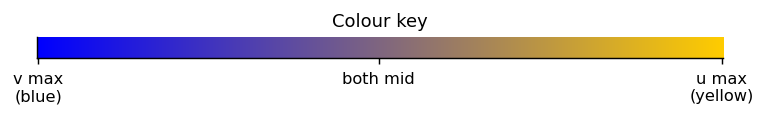

In [2]:
def make_rgb(u, v, u_scale, v_scale):
    """
    Yellow/blue RGB image.

    Parameters
    ----------
    u, v     : (n,n) float arrays
    u_scale  : normalization scale for u  (values ≥ u_scale → full yellow)
    v_scale  : normalization scale for v  (values ≥ v_scale → full blue)

    Returns
    -------
    rgb : (n, n, 3) float32  in [0, 1]
    """
    u_n = np.clip(u / (u_scale + 1e-14), 0.0, 1.0).astype(np.float32)
    v_n = np.clip(v / (v_scale + 1e-14), 0.0, 1.0).astype(np.float32)
    rgb = np.zeros(u.shape + (3,), dtype=np.float32)
    rgb[..., 0] = u_n               # R   – contributes to yellow
    rgb[..., 1] = u_n * 0.80        # G   – contributes to yellow (slightly dimmed)
    rgb[..., 2] = v_n               # B   – blue
    return rgb


def sim_scales(sim):
    """
    Return (u_scale, v_scale) from the 99th-percentile of the final frame.

    Using the 99th percentile (not max) makes the final frame fully saturated
    while ignoring rare extreme pixels.  Initial-state dots (seeded at
    V/cv or U/cu) will be ≥ scale → clipped to 1, appearing fully saturated.
    """
    u_sc = float(np.percentile(sim["final"]["u"], 99))
    v_sc = float(np.percentile(sim["final"]["v"], 99))
    # Safety floor: use physical bound if final frame is near-uniform
    u_sc = max(u_sc, sim["params"]["U"] / sim["params"]["cu"] * 0.05)
    v_sc = max(v_sc, sim["params"]["V"] / sim["params"]["cv"] * 0.05)
    return u_sc, v_sc


# ── colour key ────────────────────────────────────────────────────────────────
_x  = np.linspace(0, 1, 256)
_ku = np.outer(np.ones(64), _x)          # u increases left→right
_kv = np.outer(np.ones(64), _x[::-1])    # v increases right→left

fig_key, ax_key = plt.subplots(figsize=(6, 1.0))
ax_key.imshow(make_rgb(_ku, _kv, 1.0, 1.0),
              origin="lower", aspect="auto", interpolation="bilinear")
ax_key.set_xticks([0, 127, 255])
ax_key.set_xticklabels(
    ["v max\n(blue)", "both mid", "u max\n(yellow)"],
    fontsize=9,
)
ax_key.set_yticks([])
ax_key.set_title("Colour key", fontsize=10)
plt.tight_layout()
plt.show()

## Cell 3 — Initial-condition generators

In [3]:
def dotted_line_ic(p, n=128, y_frac=0.40,
                   dot_spacing=8, dot_radius=2.5):
    """
    Horizontal dotted line of **xanthophore** (high $v$) seeds
    on an otherwise zero background.

    Each dot is a filled circle of radius ``dot_radius`` pixels,
    centred at ``y = round(y_frac · (n-1))``, spaced ``dot_spacing``
    pixels apart in the x-direction.

    The seed amplitude equals $V / c_v$ (the physical maximum
    xanthophore density), so dots appear fully blue in the colour
    rendering.

    Parameters
    ----------
    p           : parameter dict
    n           : grid size (n × n)
    y_frac      : fractional height of the line  (0 = bottom, 1 = top)
    dot_spacing : pixel pitch between dot centres
    dot_radius  : dot radius in pixels

    Returns
    -------
    u0, v0, w0 : (n, n) float64 arrays
    """
    u0 = np.zeros((n, n))
    v0 = np.zeros((n, n))
    w0 = np.zeros((n, n))

    v_amp = p["V"] / p["cv"]                   # max possible xanthophore level
    y_c   = int(round(y_frac * (n - 1)))

    Y, X = np.ogrid[:n, :n]
    for x_c in range(0, n, dot_spacing):
        mask = (X - x_c) ** 2 + (Y - y_c) ** 2 <= dot_radius ** 2
        v0[mask] = v_amp

    return u0, v0, w0


def patch_ic(p, n=128,
             cx_frac=0.25, cy_frac=0.72,
             size_frac=0.28,
             n_dots_each=22,
             dot_radius=2.5,
             seed=42):
    """
    Square patch of randomly placed **melanophore** (high $u$) and
    **xanthophore** (high $v$) seeds on a zero background.

    The patch represents a cluster of mixed pigment cells that act as
    the nucleating seed for outward-propagating Turing patterns.

    Parameters
    ----------
    p            : parameter dict
    n            : grid size
    cx_frac      : x-centre of patch as fraction of n  (0=left, 1=right)
    cy_frac      : y-centre of patch as fraction of n  (0=bottom, 1=top)
    size_frac    : half-width of patch as fraction of n
    n_dots_each  : number of u-dots AND v-dots placed independently
    dot_radius   : dot radius in pixels
    seed         : RNG seed

    Returns
    -------
    u0, v0, w0 : (n, n) float64 arrays
    """
    u0 = np.zeros((n, n))
    v0 = np.zeros((n, n))
    w0 = np.zeros((n, n))

    u_amp = p["U"] / p["cu"]
    v_amp = p["V"] / p["cv"]
    rng   = np.random.default_rng(seed)

    half = max(int(round(size_frac * n / 2)), int(dot_radius) + 3)
    cx   = int(round(cx_frac * n))
    cy   = int(round(cy_frac * n))
    x0   = max(0, cx - half);  x1 = min(n - 1, cx + half)
    y0   = max(0, cy - half);  y1 = min(n - 1, cy + half)

    r    = int(dot_radius) + 2          # minimum margin from patch edge
    Y, X = np.ogrid[:n, :n]

    for _ in range(n_dots_each):
        # u dot
        xc = int(rng.integers(x0 + r, max(x0 + r + 1, x1 - r)))
        yc = int(rng.integers(y0 + r, max(y0 + r + 1, y1 - r)))
        u0[(X - xc) ** 2 + (Y - yc) ** 2 <= dot_radius ** 2] = u_amp
        # v dot  (independent random position)
        xc = int(rng.integers(x0 + r, max(x0 + r + 1, x1 - r)))
        yc = int(rng.integers(y0 + r, max(y0 + r + 1, y1 - r)))
        v0[(X - xc) ** 2 + (Y - yc) ** 2 <= dot_radius ** 2] = v_amp

    return u0, v0, w0


def vertical_line_ic(p, n=128, x_frac=0.40,
                     dot_spacing=8, dot_radius=2.5):
    """
    Vertical dotted line of xanthophore seeds — orientation control
    experiment (mirror of ``dotted_line_ic``).
    """
    u0 = np.zeros((n, n))
    v0 = np.zeros((n, n))
    w0 = np.zeros((n, n))

    v_amp = p["V"] / p["cv"]
    x_c   = int(round(x_frac * (n - 1)))

    Y, X = np.ogrid[:n, :n]
    for y_c in range(0, n, dot_spacing):
        mask = (X - x_c) ** 2 + (Y - y_c) ** 2 <= dot_radius ** 2
        v0[mask] = v_amp

    return u0, v0, w0

## Cell 4 — Preview: visualise the four initial conditions before running

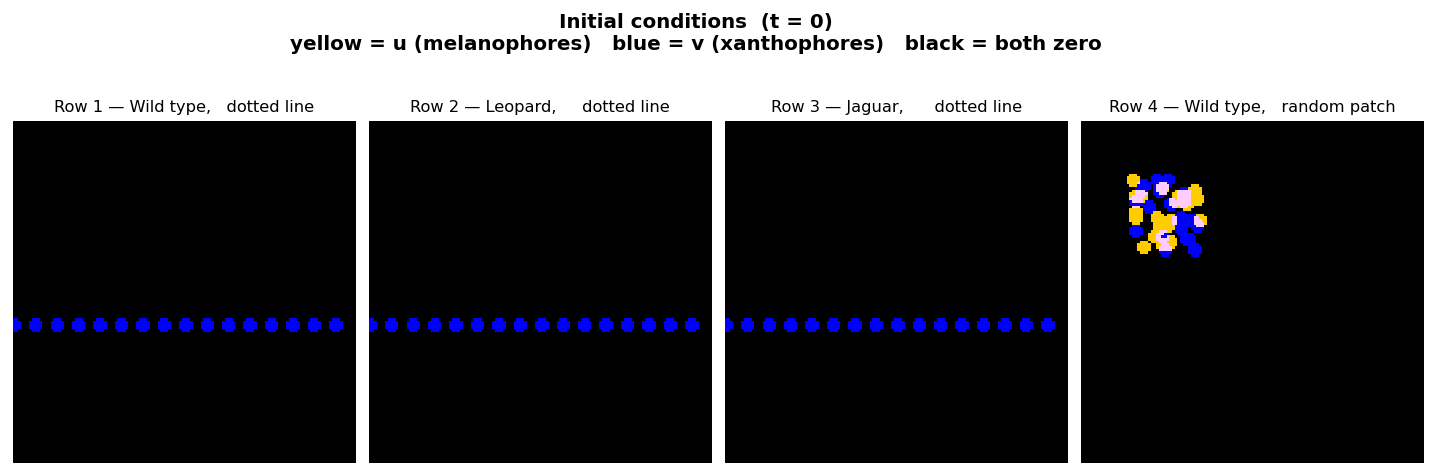

Saved  ic_t0_preview.png


In [4]:
IC_SPECS = [
    ("Row 1 — Wild type,   dotted line", WILDTYPE, "line"),
    ("Row 2 — Leopard,     dotted line", LEOPARD,  "line"),
    ("Row 3 — Jaguar,      dotted line", JAGUAR,   "line"),
    ("Row 4 — Wild type,   random patch", WILDTYPE, "patch"),
]

fig_ic0, axes_ic0 = plt.subplots(
    1, 4, figsize=(14, 3.8),
    gridspec_kw={"wspace": 0.04},
)

_IC_FIELDS = {}  # cache for later reuse

for ax, (title, p, ic_type) in zip(axes_ic0, IC_SPECS):
    if ic_type == "line":
        u0, v0, w0 = dotted_line_ic(
            p, n=128, y_frac=0.40, dot_spacing=8, dot_radius=2.5)
    else:
        u0, v0, w0 = patch_ic(
            p, n=128, cx_frac=0.25, cy_frac=0.72,
            size_frac=0.28, n_dots_each=22, seed=42)

    _IC_FIELDS[title] = (u0, v0, w0, p)

    # For display: scale to theoretical max so dots are fully saturated
    u_sc = p["U"] / p["cu"]
    v_sc = p["V"] / p["cv"]
    ax.imshow(make_rgb(u0, v0, u_sc, v_sc),
              origin="lower", aspect="equal", interpolation="nearest")
    ax.set_title(title, fontsize=9, pad=5)
    ax.axis("off")

fig_ic0.suptitle(
    "Initial conditions  (t = 0)\n"
    "yellow = u (melanophores)   blue = v (xanthophores)   black = both zero",
    fontsize=11, fontweight="bold", y=1.06,
)
plt.savefig("ic_t0_preview.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  ic_t0_preview.png")

## Cell 5 — `simulate_ic`: forward-Euler PDE from a custom initial condition

Identical physics to `simulate()` in `kondo_rd.py` but accepts any
$(u_0, v_0, w_0)$ instead of initialising near the homogeneous steady state.

The initial condition is **always** stored as the first snapshot
(`step=0, time=0`).

In [5]:
def simulate_ic(p, u0, v0, w0,
                dt=0.5,
                n_steps=60_000,
                save_every=20_000,
                verbose=True):
    """
    Explicit-Euler PDE integration on an n×n grid with Neumann BCs,
    starting from a custom initial condition.

    Parameters
    ----------
    p          : parameter dict  (WILDTYPE / LEOPARD / JAGUAR)
    u0, v0, w0 : (n, n) initial fields — may be arbitrary non-negative arrays
    dt         : time step  [must satisfy  dt ≤ 1 / (4 · max(D))]
    n_steps    : total integration steps  (T_final = n_steps · dt)
    save_every : snapshot interval in steps; t=0 is always saved
    verbose    : print progress bar

    Returns
    -------
    dict with keys
      'params'    – parameter dict
      'ic'        – copy of the initial condition
      'snapshots' – list of {'step','time','u','v','w'} dicts
                    (includes t = 0  and  every multiple of save_every)
      'final'     – state at t = T_final
    """
    n     = u0.shape[0]
    D_max = max(p["Du"], p["Dv"], p["Dw"])
    cfl   = 1.0 / (4.0 * D_max)
    if dt > cfl:
        raise ValueError(
            f"dt = {dt:.4f} exceeds the CFL stability limit "
            f"{cfl:.4f}  (D_max = {D_max}).\n"
            f"Use  dt ≤ {cfl:.4f}."
        )

    if verbose:
        print(f"\n{'═' * 56}")
        print(f"  {p['name']}  —  simulation from custom IC")
        print(f"  Grid {n}×{n}  |  dt={dt}  |  "
              f"T_final={n_steps * dt:.0f}  |  steps={n_steps:,}")
        print(f"  Snapshots at: t = 0  +  every {save_every} steps "
              f"({n_steps // save_every} additional)")
        print(f"  CFL limit: {cfl:.3f}  ✓")
        print("  Integrating:  ", end="", flush=True)

    u, v, w = u0.copy(), v0.copy(), w0.copy()
    snaps = [{"step": 0,   "time": 0.0,
               "u": u.copy(), "v": v.copy(), "w": w.copy()}]

    dot_int = max(1, n_steps // 20)

    for step in range(1, n_steps + 1):
        Lu = laplacian_neumann(u)
        Lv = laplacian_neumann(v)
        Lw = laplacian_neumann(w)

        u += dt * (F_prod(v, w, p) - p["cu"] * u + p["Du"] * Lu)
        v += dt * (G_prod(u, w, p) - p["cv"] * v + p["Dv"] * Lv)
        w += dt * (H_prod(u, v, p) - p["cw"] * w + p["Dw"] * Lw)

        np.clip(u, 0.0, None, out=u)
        np.clip(v, 0.0, None, out=v)
        np.clip(w, 0.0, None, out=w)

        if step % save_every == 0:
            snaps.append({
                "step": step,  "time": step * dt,
                "u": u.copy(), "v": v.copy(), "w": w.copy(),
            })
        if verbose and step % dot_int == 0:
            print("▪", end="", flush=True)

    final = {"step": n_steps, "time": n_steps * dt,
              "u": u.copy(), "v": v.copy(), "w": w.copy()}
    if verbose:
        print(f"\n  Done.  "
              f"u ∈ [{u.min():.2f}, {u.max():.2f}]  "
              f"v ∈ [{v.min():.2f}, {v.max():.2f}]  "
              f"w ∈ [{w.min():.2f}, {w.max():.2f}]")

    return {
        "params":    p,
        "ic":        {"u": u0.copy(), "v": v0.copy(), "w": w0.copy()},
        "snapshots": snaps,
        "final":     final,
    }

## Cell 6 — Row 1: Wild type from dotted horizontal line

A horizontal row of xanthophore seeds at $y \approx 0.40\,n$ provides a
directional template.  Wild-type parameters ($D_w \gg D_u, D_v$) favour
**horizontal stripes** with wavelength $\lambda^* \approx 2\pi / k^*$.

In [6]:
u0, v0, w0 = dotted_line_ic(
    WILDTYPE, n=128, y_frac=0.40, dot_spacing=8, dot_radius=2.5)

t_start = time.time()
sim_row1 = simulate_ic(
    WILDTYPE, u0, v0, w0,
    dt=0.5, n_steps=60_000, save_every=20_000,
)
print(f"  Wall time: {time.time() - t_start:.1f} s")


════════════════════════════════════════════════════════
  Wild Type  —  simulation from custom IC
  Grid 128×128  |  dt=0.5  |  T_final=30000  |  steps=60,000
  Snapshots at: t = 0  +  every 20000 steps (3 additional)
  CFL limit: 1.250  ✓
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.33, 5.82]  v ∈ [0.48, 8.65]  w ∈ [1.11, 4.06]
  Wall time: 34.0 s


## Cell 7 — Row 2: Leopard mutant from the same dotted line

The only change is $c_3 = 0.385$ (vs $0.370$ in wild type).
This small increase in baseline $u$-production shifts the preferred
pattern topology from **stripes** to **spots**.
The initial horizontal line still biases the spatial arrangement,
but the leopard parameters ultimately drive spot formation.

In [7]:
u0, v0, w0 = dotted_line_ic(
    LEOPARD, n=128, y_frac=0.40, dot_spacing=8, dot_radius=2.5)

t_start = time.time()
sim_row2 = simulate_ic(
    LEOPARD, u0, v0, w0,
    dt=0.5, n_steps=60_000, save_every=20_000,
)
print(f"  Wall time: {time.time() - t_start:.1f} s")


════════════════════════════════════════════════════════
  Leopard Mutant  —  simulation from custom IC
  Grid 128×128  |  dt=0.5  |  T_final=30000  |  steps=60,000
  Snapshots at: t = 0  +  every 20000 steps (3 additional)
  CFL limit: 1.250  ✓
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.45, 6.01]  v ∈ [0.08, 8.23]  w ∈ [1.57, 4.94]
  Wall time: 31.3 s


## Cell 8 — Row 3: Jaguar / Obelix mutant from the same dotted line

All diffusion constants are doubled ($D_u = D_v = 0.04$, $D_w = 0.40$).
The dominant wavenumber $k^*$ shifts to smaller values, so
$\lambda^* = 2\pi / k^*$ is **larger** — yielding wider horizontal stripes.

In [8]:
u0, v0, w0 = dotted_line_ic(
    JAGUAR, n=128, y_frac=0.40, dot_spacing=8, dot_radius=2.5)

t_start = time.time()
sim_row3 = simulate_ic(
    JAGUAR, u0, v0, w0,
    dt=0.5, n_steps=60_000, save_every=20_000,
)
print(f"  Wall time: {time.time() - t_start:.1f} s")


════════════════════════════════════════════════════════
  Jaguar/Obelix Mutant  —  simulation from custom IC
  Grid 128×128  |  dt=0.5  |  T_final=30000  |  steps=60,000
  Snapshots at: t = 0  +  every 20000 steps (3 additional)
  CFL limit: 0.625  ✓
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.26, 5.84]  v ∈ [0.42, 8.88]  w ∈ [0.98, 4.11]
  Wall time: 39.4 s


## Cell 9 — Row 4: Wild type from a random mixed patch

A square patch (upper-left quadrant) contains randomly placed
melanophore and xanthophore seeds.  The isotropic, irregular
initial condition produces **labyrinthine stripes** that propagate
outward from the patch as both species spread and interact.

In [9]:
u0, v0, w0 = patch_ic(
    WILDTYPE, n=128,
    cx_frac=0.25, cy_frac=0.72,
    size_frac=0.28, n_dots_each=22, seed=42,
)

t_start = time.time()
sim_row4 = simulate_ic(
    WILDTYPE, u0, v0, w0,
    dt=0.5, n_steps=60_000, save_every=20_000,
)
print(f"  Wall time: {time.time() - t_start:.1f} s")

# ── collect all rows ──────────────────────────────────────────────────────────
ALL_IC_SIMS = [sim_row1, sim_row2, sim_row3, sim_row4]
ROW_LABELS  = [
    "Row 1 — Wild type\n(dotted line)",
    "Row 2 — Leopard\n(dotted line)",
    "Row 3 — Jaguar\n(dotted line)",
    "Row 4 — Wild type\n(random patch)",
]

print("\nAll simulations complete.")
for sim, lbl in zip(ALL_IC_SIMS, ROW_LABELS):
    us, vs = sim_scales(sim)
    print(f"  {lbl.splitlines()[0]:<28}  "
          f"u_scale={us:.2f}  v_scale={vs:.2f}")


════════════════════════════════════════════════════════
  Wild Type  —  simulation from custom IC
  Grid 128×128  |  dt=0.5  |  T_final=30000  |  steps=60,000
  Snapshots at: t = 0  +  every 20000 steps (3 additional)
  CFL limit: 1.250  ✓
  Integrating:  ▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪▪
  Done.  u ∈ [0.14, 6.18]  v ∈ [0.24, 9.36]  w ∈ [0.64, 4.46]
  Wall time: 32.3 s

All simulations complete.
  Row 1 — Wild type             u_scale=5.82  v_scale=8.58
  Row 2 — Leopard               u_scale=5.91  v_scale=7.60
  Row 3 — Jaguar                u_scale=5.84  v_scale=8.80
  Row 4 — Wild type             u_scale=5.84  v_scale=8.89


## Cell 10 — Main figure: reproduce the 4 × 4 panel layout

**Layout:** `Initial Pattern  ▷  [early]  ▷  [mid]  ▷  Stable Pattern`

- Four image columns interleaved with three narrow arrow columns in GridSpec.
- Colour normalised per row to the 99th-percentile of the final frame
  so that the initial near-zero background is black and the final
  pattern has full contrast.

/tmp/ipykernel_433/3939336269.py:102: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


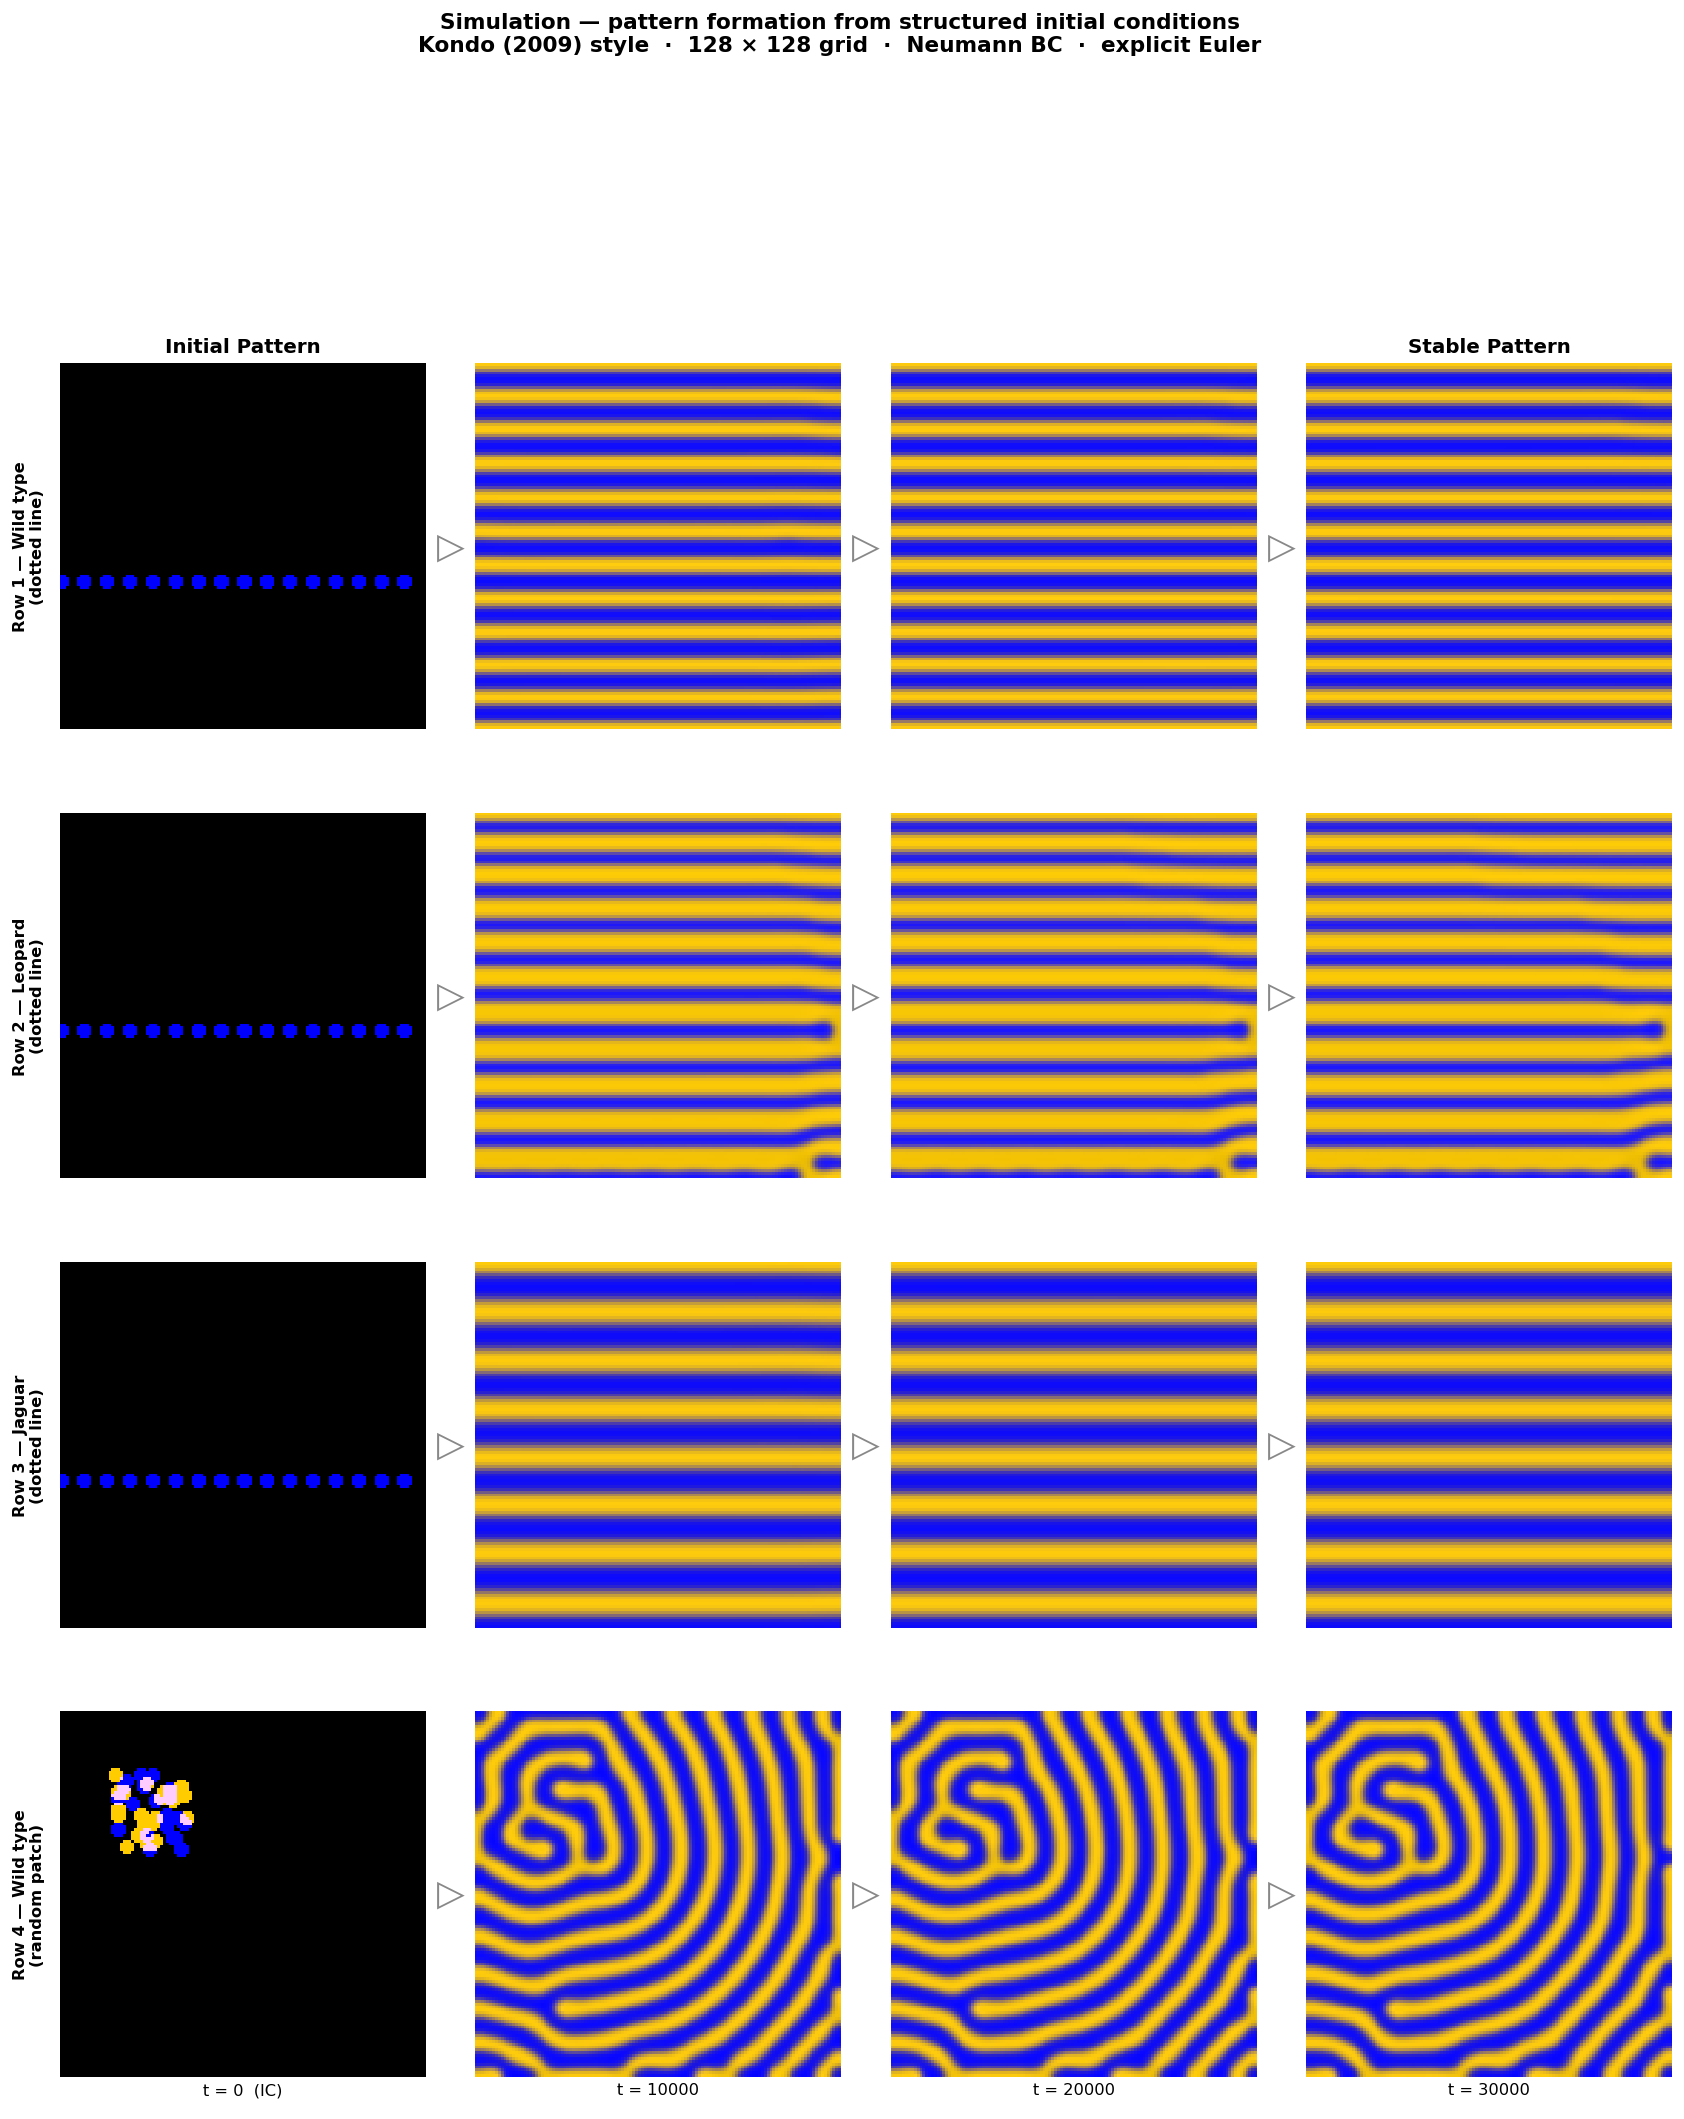

Figure saved to  ic_patterns_kondo2009.png


In [10]:
def pick_4_frames(snaps):
    """
    Select 4 representative snapshots from a list:
    initial, 1/3, 2/3, and final.
    """
    n = len(snaps)
    if n >= 4:
        return [
            snaps[0],
            snaps[max(1,     n // 3)],
            snaps[max(2, 2 * n // 3)],
            snaps[n - 1],
        ]
    frames = list(snaps)
    while len(frames) < 4:
        frames.append(snaps[-1])
    return frames


def plot_ic_figure(sims, row_labels, save_path=None):
    """
    Reproduce the supplementary-figure style:
    4 rows × (4 image + 3 arrow) = 7 GridSpec columns.

    Parameters
    ----------
    sims       : list of simulation result dicts
    row_labels : list of row label strings (one per sim)
    save_path  : filename to save  (None = no save)
    """
    N_ROWS = len(sims)

    # GridSpec column layout:  img | arrow | img | arrow | img | arrow | img
    col_widths = [1, 0.10, 1, 0.10, 1, 0.10, 1]
    img_gcols  = [0, 2, 4, 6]
    arr_gcols  = [1, 3, 5]

    fig = plt.figure(figsize=(16, 4.2 * N_ROWS + 0.9))
    gs  = gridspec.GridSpec(
        N_ROWS, len(col_widths),
        figure=fig,
        width_ratios=col_widths,
        hspace=0.06,
        wspace=0.03,
    )

    for row_i, (sim, rlabel) in enumerate(zip(sims, row_labels)):
        p      = sim["params"]
        frames = pick_4_frames(sim["snapshots"])
        us, vs = sim_scales(sim)

        # ── image columns ────────────────────────────────────────────────────
        for col_i, (frame, gc) in enumerate(zip(frames, img_gcols)):
            ax  = fig.add_subplot(gs[row_i, gc])
            rgb = make_rgb(frame["u"], frame["v"], us, vs)
            ax.imshow(rgb, origin="lower", aspect="equal",
                      interpolation="nearest")
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)

            # column header  (top row only)
            if row_i == 0:
                if col_i == 0:
                    ax.set_title("Initial Pattern",
                                 fontsize=11, fontweight="bold", pad=6)
                elif col_i == 3:
                    ax.set_title("Stable Pattern",
                                 fontsize=11, fontweight="bold", pad=6)

            # time label below image  (bottom row only)
            if row_i == N_ROWS - 1:
                t_val = frame["time"]
                ax.set_xlabel(
                    f"t = {t_val:.0f}" if t_val > 0 else "t = 0  (IC)",
                    fontsize=9, labelpad=3,
                )

            # row label on the left edge  (first image column only)
            if col_i == 0:
                ax.set_ylabel(rlabel,
                              fontsize=9, fontweight="bold",
                              rotation=90, labelpad=8)

        # ── arrow columns ────────────────────────────────────────────────────
        for gc_arr in arr_gcols:
            ax_a = fig.add_subplot(gs[row_i, gc_arr])
            ax_a.text(0.5, 0.5, "▷",
                      ha="center", va="center",
                      fontsize=20, color="#888888",
                      transform=ax_a.transAxes)
            ax_a.axis("off")

    # ── overall title ────────────────────────────────────────────────────────
    fig.suptitle(
        "Simulation — pattern formation from structured initial conditions\n"
        "Kondo (2009) style  ·  128 × 128 grid  ·  Neumann BC  ·  explicit Euler",
        fontsize=12, fontweight="bold", y=1.02,
    )

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig


fig_main = plot_ic_figure(
    ALL_IC_SIMS, ROW_LABELS,
    save_path="ic_patterns_kondo2009.png",
)
plt.show()
print("Figure saved to  ic_patterns_kondo2009.png")

## Cell 11 — Side-by-side initial vs stable for each row

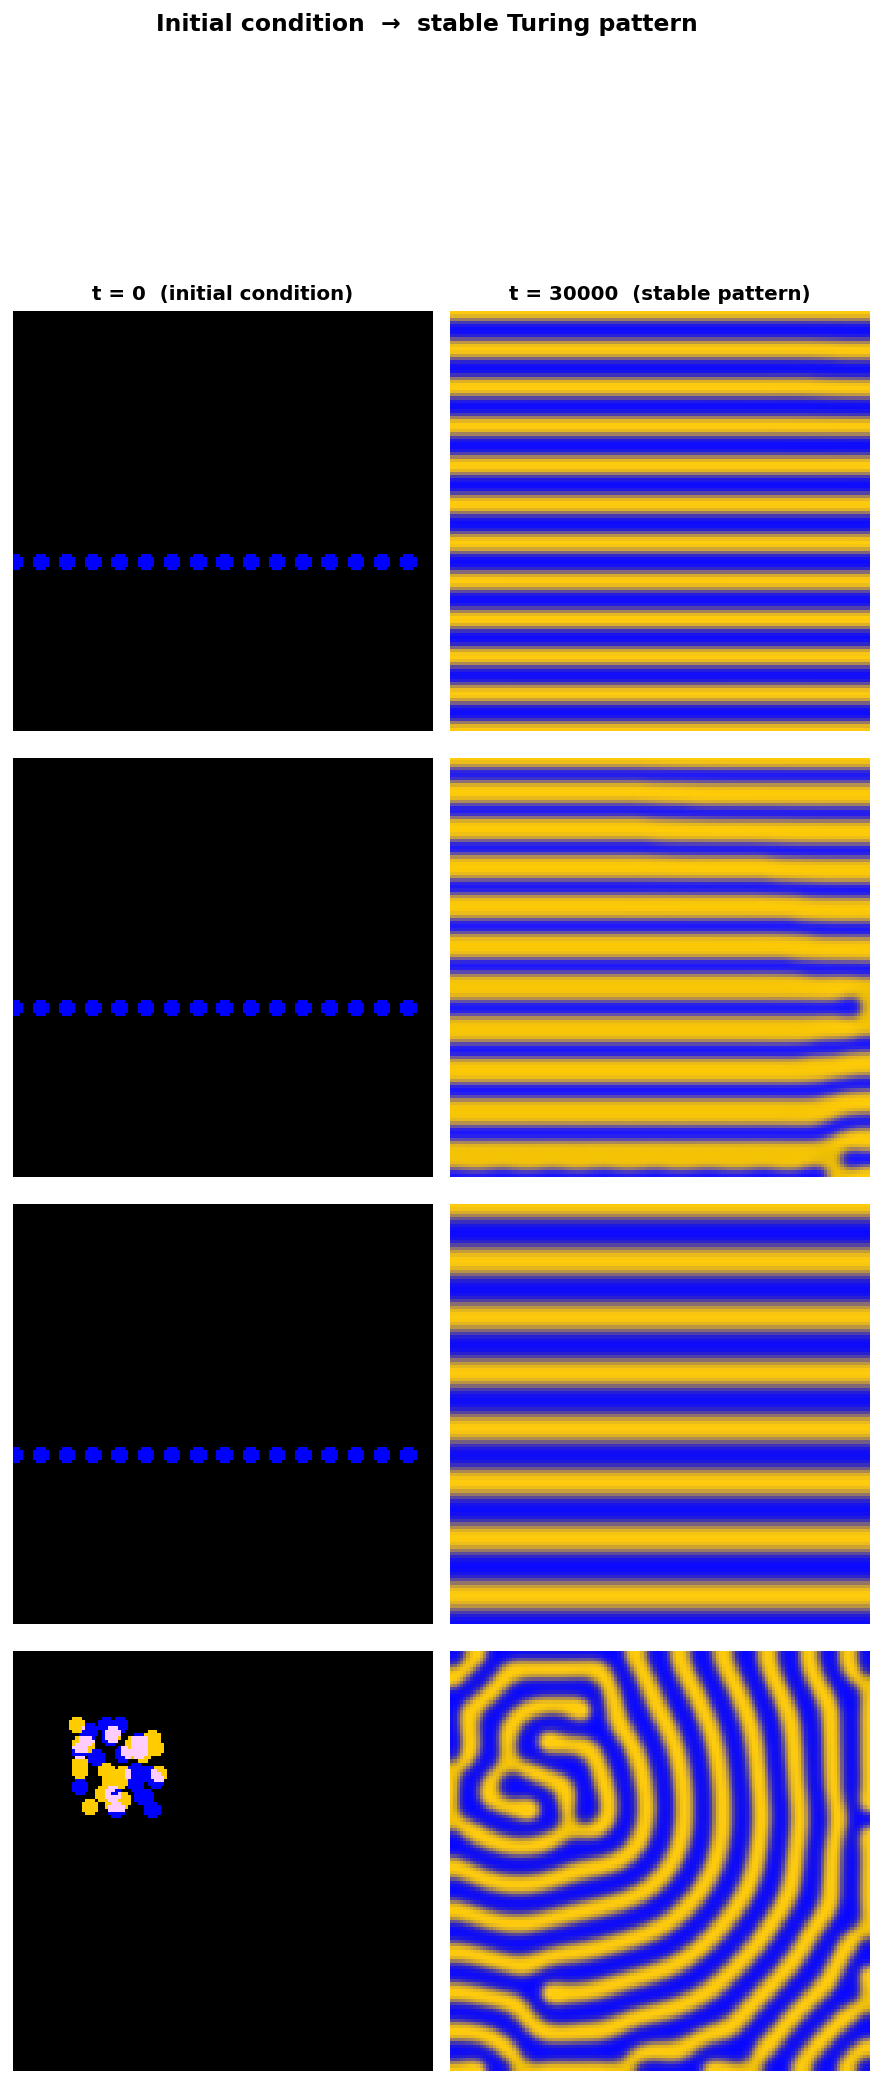

Saved  ic_vs_stable_kondo2009.png


In [11]:
fig_compare, axes_cmp = plt.subplots(
    N_ROWS := len(ALL_IC_SIMS), 2,
    figsize=(8.5, 4.4 * len(ALL_IC_SIMS)),
    gridspec_kw={"hspace": 0.06, "wspace": 0.04},
)

for row_i, (sim, rlabel) in enumerate(zip(ALL_IC_SIMS, ROW_LABELS)):
    p      = sim["params"]
    us, vs = sim_scales(sim)
    ic     = sim["ic"]
    fin    = sim["final"]

    for col_i, (fld, ttl) in enumerate([
        (ic,  "t = 0  (initial condition)"),
        (fin, f"t = {fin['time']:.0f}  (stable pattern)"),
    ]):
        ax = axes_cmp[row_i, col_i]
        ax.imshow(make_rgb(fld["u"], fld["v"], us, vs),
                  origin="lower", aspect="equal", interpolation="nearest")
        ax.axis("off")

        if row_i == 0:
            ax.set_title(ttl, fontsize=11, fontweight="bold", pad=6)
        if col_i == 0:
            ax.set_ylabel(rlabel, fontsize=9, fontweight="bold",
                          rotation=90, labelpad=8)

fig_compare.suptitle(
    "Initial condition  →  stable Turing pattern",
    fontsize=13, fontweight="bold", y=1.01,
)
plt.savefig("ic_vs_stable_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  ic_vs_stable_kondo2009.png")

## Cell 12 — Does dot spacing control stripe orientation?

The line IC enforces horizontal stripes when the dot pitch is
**below** the natural wavelength $\lambda^*$: all dots "feel" each other
through diffusion and form a coherent horizontal template.
When the pitch **exceeds** $\lambda^*$, the dots are too far apart to
interact coherently and stripes may form at other orientations.

We test three pitches: $0.5\lambda^*$, $\lambda^*$, and $1.8\lambda^*$.

Wild-type dominant wavenumber:  k* = 0.5483
Wild-type dominant wavelength:  λ* = 11.46  grid units

Testing spacings: [('0.5 λ* (6 px)', 6), ('1.0 λ* (11 px)', 11), ('1.8 λ* (21 px)', 21)]
  spacing=6 px  done  (u_max=5.82, v_max=8.66)
  spacing=11 px  done  (u_max=5.82, v_max=8.66)
  spacing=21 px  done  (u_max=5.92, v_max=9.37)


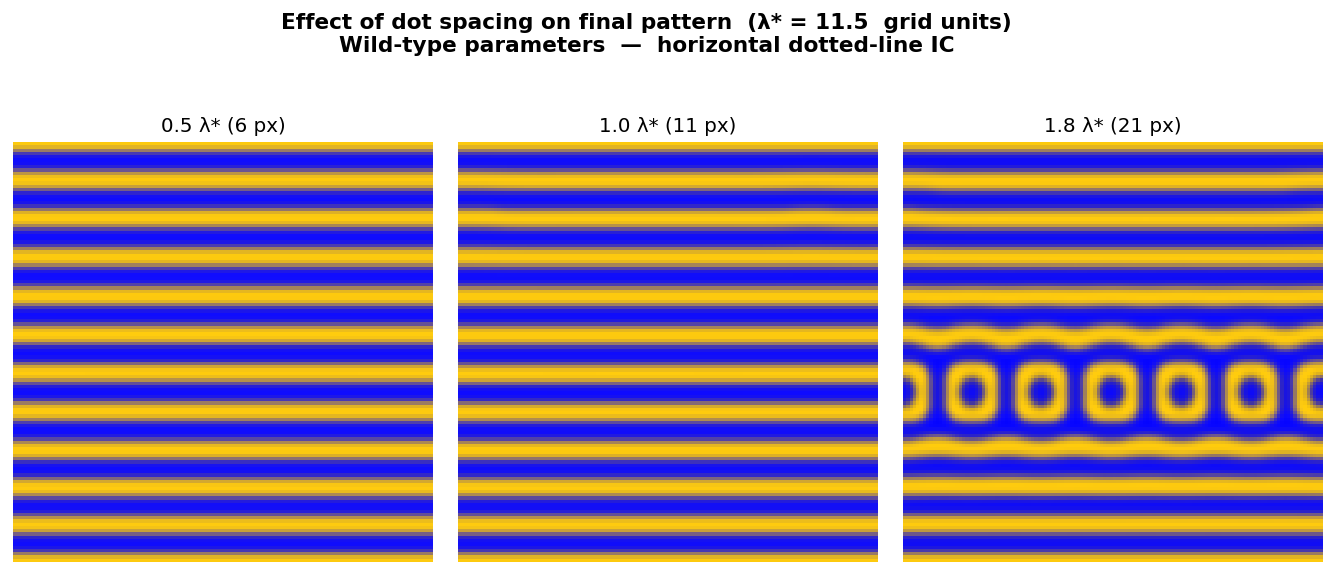

Saved  spacing_effect_kondo2009.png


In [12]:
# ── compute λ* for wild type ──────────────────────────────────────────────────
k_arr, sigma_arr = dispersion_relation(WILDTYPE, k_max=2.5, n_k=3000)
_pos    = sigma_arr > 0
_k_star = float(k_arr[np.argmax(np.where(k_arr > 0, sigma_arr, -np.inf))])
lam_star = 2.0 * np.pi / _k_star

print(f"Wild-type dominant wavenumber:  k* = {_k_star:.4f}")
print(f"Wild-type dominant wavelength:  λ* = {lam_star:.2f}  grid units")

SPACINGS = {
    f"0.5 λ* ({int(round(0.5 * lam_star))} px)":  int(round(0.5  * lam_star)),
    f"1.0 λ* ({int(round(1.0 * lam_star))} px)":  int(round(1.0  * lam_star)),
    f"1.8 λ* ({int(round(1.8 * lam_star))} px)":  int(round(1.8  * lam_star)),
}

# Clamp to [2, n//3]
SPACINGS = {k: max(2, min(v, 128 // 3)) for k, v in SPACINGS.items()}
print(f"\nTesting spacings: {list(SPACINGS.items())}")

spacing_sims = {}
for label, sp in SPACINGS.items():
    u0, v0, w0 = dotted_line_ic(WILDTYPE, n=128, y_frac=0.40,
                                  dot_spacing=sp, dot_radius=2.5)
    s = simulate_ic(WILDTYPE, u0, v0, w0,
                    dt=0.5, n_steps=60_000, save_every=60_000,
                    verbose=False)
    spacing_sims[label] = s
    print(f"  spacing={sp} px  done  "
          f"(u_max={s['final']['u'].max():.2f}, "
          f"v_max={s['final']['v'].max():.2f})")

# ── plot ──────────────────────────────────────────────────────────────────────
fig_sp, axes_sp = plt.subplots(
    1, 3, figsize=(13, 4.8),
    gridspec_kw={"wspace": 0.06},
)

for ax, (label, sim) in zip(axes_sp, spacing_sims.items()):
    us, vs = sim_scales(sim)
    ax.imshow(
        make_rgb(sim["final"]["u"], sim["final"]["v"], us, vs),
        origin="lower", aspect="equal", interpolation="nearest",
    )
    ax.set_title(label, fontsize=11)
    ax.axis("off")

fig_sp.suptitle(
    f"Effect of dot spacing on final pattern  (λ* = {lam_star:.1f}  grid units)\n"
    "Wild-type parameters  —  horizontal dotted-line IC",
    fontsize=12, fontweight="bold", y=1.04,
)
plt.savefig("spacing_effect_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  spacing_effect_kondo2009.png")

## Cell 13 — Does line orientation control stripe orientation?

Comparing a **horizontal** vs **vertical** dotted line for the wild-type
parameters.  Because Turing patterns are isotropic by default, the
first-forming direction is determined by the initial symmetry breaking.

Running horizontal vs vertical line comparison …
  Horizontal line: 40.7 s
  Vertical line:   46.0 s


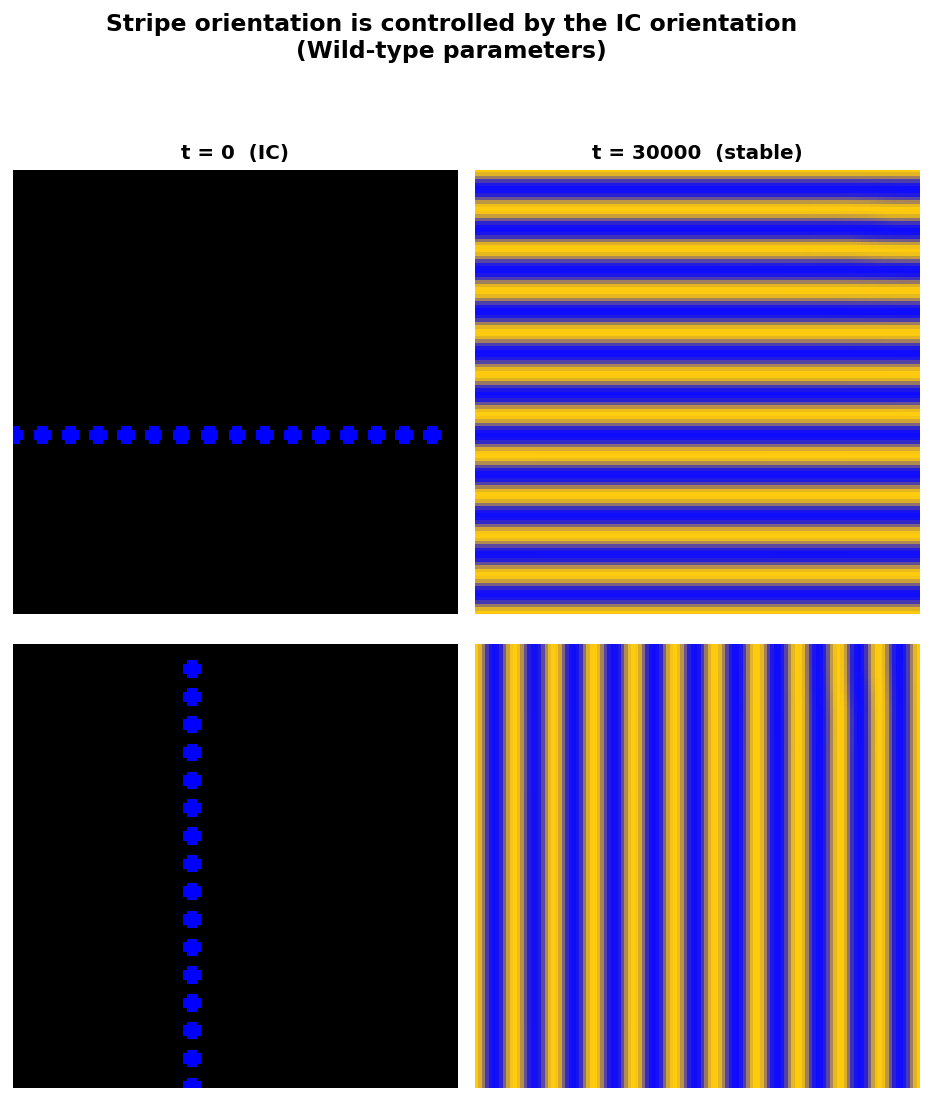

Saved  orientation_effect_kondo2009.png


In [13]:
print("Running horizontal vs vertical line comparison …")

t0 = time.time()
u0h, v0h, w0h = dotted_line_ic(WILDTYPE, n=128, y_frac=0.40,
                                 dot_spacing=8, dot_radius=2.5)
sim_horiz = simulate_ic(WILDTYPE, u0h, v0h, w0h,
                         dt=0.5, n_steps=60_000, save_every=60_000,
                         verbose=False)
print(f"  Horizontal line: {time.time()-t0:.1f} s")

t0 = time.time()
u0v, v0v, w0v = vertical_line_ic(WILDTYPE, n=128, x_frac=0.40,
                                   dot_spacing=8, dot_radius=2.5)
sim_vert = simulate_ic(WILDTYPE, u0v, v0v, w0v,
                        dt=0.5, n_steps=60_000, save_every=60_000,
                        verbose=False)
print(f"  Vertical line:   {time.time()-t0:.1f} s")

# ── 2×2 figure: IC | stable for each orientation ─────────────────────────────
fig_ori, axes_ori = plt.subplots(
    2, 2, figsize=(9, 9.2),
    gridspec_kw={"hspace": 0.06, "wspace": 0.04},
)

for row_i, (sim, orient) in enumerate([
    (sim_horiz, "Horizontal line → horizontal stripes"),
    (sim_vert,  "Vertical line   → vertical stripes"),
]):
    us, vs = sim_scales(sim)
    for col_i, (fld, ttl) in enumerate([
        (sim["ic"],    "t = 0  (IC)"),
        (sim["final"], f"t = {sim['final']['time']:.0f}  (stable)"),
    ]):
        ax = axes_ori[row_i, col_i]
        ax.imshow(make_rgb(fld["u"], fld["v"], us, vs),
                  origin="lower", aspect="equal", interpolation="nearest")
        ax.axis("off")
        if row_i == 0:
            ax.set_title(ttl, fontsize=11, fontweight="bold", pad=6)
        if col_i == 0:
            ax.set_ylabel(orient, fontsize=10, fontweight="bold",
                          rotation=90, labelpad=8)

fig_ori.suptitle(
    "Stripe orientation is controlled by the IC orientation\n"
    "(Wild-type parameters)",
    fontsize=13, fontweight="bold", y=1.01,
)
plt.savefig("orientation_effect_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  orientation_effect_kondo2009.png")

## Cell 14 — Quantitative: radial power spectra of the IC simulations

Each panel compares $\hat{u}(k_x, 0)$ (horizontal cross-section through
the 2-D FFT) to verify that the dominant spatial frequency in the
simulation matches the dispersion-relation prediction $k^*$.

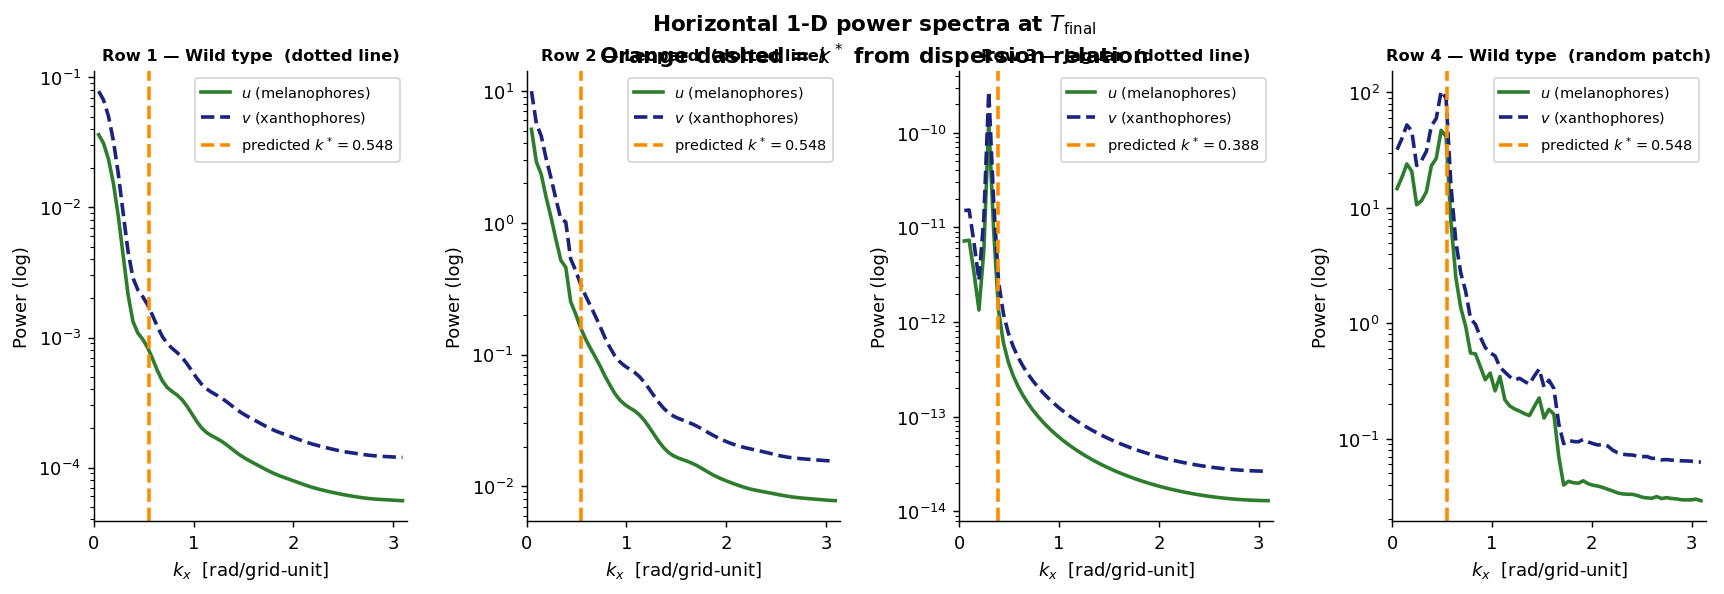

Saved  power_spectra_ic_kondo2009.png


In [14]:
def horizontal_power_spectrum(field, dx=1.0):
    """
    1-D power spectrum along the $k_x$ axis (horizontal slice of 2-D FFT).

    Returns
    -------
    k_pos  : 1-D array  positive wavenumbers in  rad / grid-unit
    P_pos  : 1-D array  power at each positive wavenumber
    """
    row_fft  = np.fft.fft(field, axis=1)   # FFT along x for each row
    P_2d     = np.abs(row_fft) ** 2 / field.shape[1]
    P_mean   = P_2d.mean(axis=0)           # average over rows (y-axis)
    P_shifted = np.fft.fftshift(P_mean)
    k_all    = np.fft.fftshift(np.fft.fftfreq(field.shape[1], d=dx)) * 2 * np.pi
    pos_mask = k_all > 0
    return k_all[pos_mask], P_shifted[pos_mask]


fig_ps, axes_ps = plt.subplots(
    1, 4, figsize=(16, 4.5),
    gridspec_kw={"wspace": 0.38},
    sharey=False,
)

colours = ["steelblue", "crimson", "seagreen", "darkorange"]

for ax, sim, lbl, col in zip(axes_ps, ALL_IC_SIMS, ROW_LABELS, colours):
    fin   = sim["final"]
    p     = sim["params"]

    k_u, P_u = horizontal_power_spectrum(fin["u"])
    k_v, P_v = horizontal_power_spectrum(fin["v"])

    P_u = np.maximum(P_u, 1e-30)
    P_v = np.maximum(P_v, 1e-30)

    ax.semilogy(k_u, P_u, color="#2e7d2e", lw=2.0, label="$u$ (melanophores)")
    ax.semilogy(k_v, P_v, color="#1a237e", lw=2.0, ls="--",
                label="$v$ (xanthophores)")

    # Predicted k* from dispersion relation
    k_d, sig_d = dispersion_relation(p, k_max=2.5, n_k=3000)
    _kstar = float(k_d[np.argmax(np.where(k_d > 0, sig_d, -np.inf))])
    ax.axvline(_kstar, color="darkorange", lw=2.0, ls="--",
               label=f"predicted $k^*={_kstar:.3f}$")

    ax.set_xlim(0, np.pi)
    ax.set_xlabel(r"$k_x$  [rad/grid-unit]", fontsize=10)
    ax.set_ylabel("Power (log)", fontsize=10)
    ax.set_title(lbl.replace("\n", "  "), fontsize=9, fontweight="bold")
    ax.legend(fontsize=8, loc="upper right")

fig_ps.suptitle(
    r"Horizontal 1-D power spectra at $T_\mathrm{final}$"
    "\nOrange dashed = $k^*$ from dispersion relation",
    fontsize=12, fontweight="bold",
)
plt.savefig("power_spectra_ic_kondo2009.png", dpi=130, bbox_inches="tight")
plt.show()
print("Saved  power_spectra_ic_kondo2009.png")

## Cell 15 — Summary table

In [15]:
print("=" * 72)
print("  SUMMARY: IC-SIMULATION RESULTS")
print("=" * 72)
fmt = "  {:<26s} {:>10s} {:>12s} {:>12s} {:>12s}"
print(fmt.format("Row", "IC type", "u_mean", "v_mean", "corr(u,v)"))
print("  " + "─" * 70)

row_ic_types = ["horiz. line", "horiz. line", "horiz. line", "rand. patch"]

for sim, rlabel, ic_type in zip(ALL_IC_SIMS, ROW_LABELS, row_ic_types):
    fin  = sim["final"]
    ur   = fin["u"].ravel()
    vr   = fin["v"].ravel()
    corr = float(np.corrcoef(ur, vr)[0, 1])
    print(fmt.format(
        rlabel.splitlines()[0],
        ic_type,
        f"{ur.mean():.4f}",
        f"{vr.mean():.4f}",
        f"{corr:+.4f}",
    ))

print()
print("  Expected:  corr(u,v) ≪ 0  → u and v occupy complementary domains.")
print("  Leopard:   spot topology → deeper negative correlation than WT stripes.")

  SUMMARY: IC-SIMULATION RESULTS
  Row                           IC type       u_mean       v_mean    corr(u,v)
  ──────────────────────────────────────────────────────────────────────
  Row 1 — Wild type          horiz. line       2.9405       4.4369      -0.9973
  Row 2 — Leopard            horiz. line       3.7459       3.0380      -0.9990
  Row 3 — Jaguar             horiz. line       2.9109       4.4954      -0.9972
  Row 4 — Wild type          rand. patch       2.9150       4.4773      -0.9966

  Expected:  corr(u,v) ≪ 0  → u and v occupy complementary domains.
  Leopard:   spot topology → deeper negative correlation than WT stripes.


## Summary

### What the structured IC simulations demonstrate

| Observation | Mechanism |
|-------------|-----------|
| Horizontal line → horizontal stripes (rows 1, 3) | The line breaks rotational symmetry; nearby dots couple through diffusion to create a coherent template below $\lambda^*$ pitch |
| Same line → spots in leopard (row 2) | The preferred topology is set by the reaction kinetics ($c_3$), not by the IC; the IC only biases spatial arrangement |
| Jaguar produces wider stripes (row 3 vs row 1) | Larger diffusion coefficients shift $k^*$ downward → $\lambda^* = 2\pi/k^*$ increases |
| Random patch → labyrinthine stripes (row 4) | No preferred orientation → Turing modes grow in multiple directions simultaneously; pattern propagates outward from the seed |
| Spacing $\gg \lambda^*$ breaks orientation control | Dots cannot interact coherently; pattern nucleates independently at each dot |
| Horizontal vs vertical line → orthogonal stripes | Confirms that orientation is not intrinsic to the parameters but set by the IC |

### File outputs

| File | Content |
|------|---------|
| `ic_t0_preview.png` | Four initial conditions at $t=0$ |
| `ic_patterns_kondo2009.png` | **Main figure**: 4 rows × 4 time columns |
| `ic_vs_stable_kondo2009.png` | IC vs final state side-by-side |
| `spacing_effect_kondo2009.png` | Pattern at 0.5 / 1 / 1.8 × $\lambda^*$ dot spacing |
| `orientation_effect_kondo2009.png` | Horizontal vs vertical line → orthogonal stripes |
| `power_spectra_ic_kondo2009.png` | Power spectra vs predicted $k^*$ |